In [2]:
%load_ext autoreload
%autoreload 2

In [34]:
import os, sys, re, random, time
import importlib, traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils import data

import data_loaders
import miscellaneous
from rs_algorithm.models import RegressionBasedBPEModel, ThreeTowerRecommender
from rs_algorithm.models import AdaptiveRepresentation, SequenceRepresentation
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel
from dl_trainer import Trainer, split_collate

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [44]:
try:
    ds_train = data_model.get_dataset()
    smaller_matrix = miscellaneous.keyed_cache("kuairec_smaller_matrix", lambda: data_model.subsample_specimen('small', 10000))
    ds_test = data_model.get_bpr_dataset(smaller_matrix)
except:
    traceback.print_exc()

In [6]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=d_embed, id2idx=iid2idx)
    model = RegressionBasedBPEModel(user_model, item_model)
except:
    traceback.print_exc()

In [35]:
try:
    trainer = Trainer(model=model, train_dataloader=data.DataLoader(ds_train, batch_size=8192))
except:
    traceback.print_exc()

In [36]:
try:
    trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
except:
    traceback.print_exc()

In [37]:
try:
    history_model = SequenceRepresentation('mean', d_embed, d_embed)
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = True
    recommender = ThreeTowerRecommender(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [46]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_test))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0)
        hft = torch.cat([nif, nif, nif], dim=0)
        msk = torch.ones((1, 3))
        emb = recommender(uid, uft, hid, hft, msk)

        uem, _ = user_model(uid, uft)
        pie, _ = item_model(pid, pif)
        nie, _ = item_model(nid, nif)

        print((uem * pie).mean())
        print((uem * nie).mean())
        print((uem * emb).mean())
except:
    traceback.print_exc()

tensor(-0.0491)
tensor(0.0265)
tensor(0.2832)


In [21]:
class UserModelDataset(data.Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1000, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))[0].numpy()
            self.users[uid] = DynamicPreferenceUserModel(uem)

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)
        user = self.users[user_id]
        user.reset()
        hist_id = []
        hist_feats = []
        click_hist = []
        for iid in self.ratings.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))[0].numpy()
                click_hist.append(user.react(None, None, iem))
        hist_id = np.array(hist_id, dtype=np.int64)
        hist_feats = np.array(hist_feats, dtype=np.float32)
        # click_hist = np.array(click_hist, dtype=np.float32)
        # TODO: Convert item history to interaction hostory by multiplying with +-1
        return ((user_id, user_feats, hist_id, hist_feats, np.int64(hist_id.shape[0])),
                (user.preference.flatten(), np.float32(click_hist[-1])))


try:
    umd = UserModelDataset(data_model, 20)
except:
    traceback.print_exc()

In [23]:
def bce_loss(preds, truth):
    uem = preds
    pref, clk = truth
    # print('uem', uem.shape, 'pref', pref.shape, 'clk', clk.shape)
    rel = torch.sigmoid((uem * pref).sum(dim=1))
    # print('rel', rel.shape)
    return F.binary_cross_entropy(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, seq = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(seq)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    prf, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    prf = torch.tensor(prf)
    clk = torch.tensor(clk)
    return (uid, uft, hid, hft, mask), (prf, clk)

In [24]:
loss = None

In [28]:
try:
    trainer = Trainer(
        model=recommender,
        train_dataloader=data.DataLoader(umd, batch_size=256, collate_fn=collate_fn),
        epochs=10,
        criterion=bce_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0001),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [31]:
try:
    trainer.train()
except:
    traceback.print_exc()

Epoch:  0/10    Train Loss: 44.53    TTS: 7.19    ETA: 280.28
Epoch:  0/10    Train Loss: 42.19    TTS: 14.28    ETA: 271.32
Epoch:  0/10    Train Loss: 48.05    TTS: 21.44    ETA: 264.38
Epoch:  1/10    Train Loss: 50.00    TTS: 27.92    ETA: 251.25
Epoch:  1/10    Train Loss: 46.19    TTS: 27.92    ETA: 251.26
Epoch:  1/10    Train Loss: 48.44    TTS: 35.17    ETA: 246.16
Epoch:  1/10    Train Loss: 48.05    TTS: 42.28    ETA: 239.58
Epoch:  1/10    Train Loss: 45.31    TTS: 49.51    ETA: 233.40
Epoch:  2/10    Train Loss: 49.14    TTS: 56.02    ETA: 224.08
Epoch:  2/10    Train Loss: 47.73    TTS: 56.02    ETA: 224.08
Epoch:  2/10    Train Loss: 47.27    TTS: 63.18    ETA: 217.61
Epoch:  2/10    Train Loss: 51.95    TTS: 70.27    ETA: 210.82
Epoch:  2/10    Train Loss: 45.31    TTS: 77.38    ETA: 203.99
Epoch:  3/10    Train Loss: 47.41    TTS: 83.88    ETA: 195.72
Epoch:  3/10    Train Loss: 47.99    TTS: 83.88    ETA: 195.72
Epoch:  3/10    Train Loss: 51.95    TTS: 90.91    ETA: 

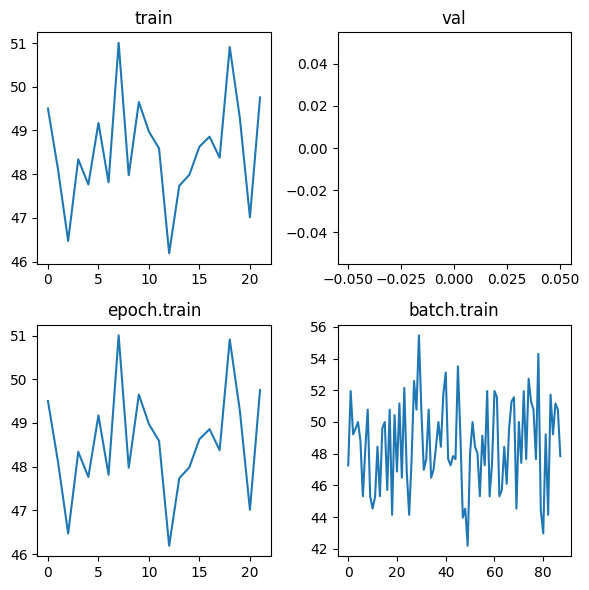

In [32]:
try:
    _, axs = plt.subplots(2, 2, figsize=(6, 6))
    for ax, data in zip(axs.flatten(), trainer.loss):
        miscellaneous.plot_data(trainer.loss[data], title=data, ax=ax)
    plt.tight_layout(), plt.show()
except:
    traceback.print_exc()